# Predicting Customer Insurance Product Preference and Channel-Affinity
### Business Analytics Case Study — Full Analysis Notebook

## 1. Load Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

df = pd.read_excel('Insurance_Survey_Fused_Dataset.xlsx')
print("Raw shape:", df.shape)
df.head()

Raw shape: (10000, 30)


,Timestamp,Age_Group,Gender,Area_Type,City,Income_Category,Occupation,Marital_Status,Dependents,Life_Event_Past,...,Digital_Comfort,Would_Switch_Channel,Likelihood_Car,Likelihood_Health,Likelihood_TermLife,Likelihood_Investment,Likelihood_Retirement,Financial_Literacy,Attention_Check,Source
0,2026-08-20 09:00:00,46-60,Male,Urban (city),Bengaluru,"Above ₹1,00,000",Salaried employee,Married with children,3–4,None of these,...,4.0,No,2,3,3,1,2,2.0,Online,synthetic
1,2026-08-20 09:04:00,46-60,Male,Rural (village),Sathyamangalam,"Above ₹1,00,000",Salaried employee,Married with children,5 or more,Changed job / started a new career,...,2.0,No,3,1,2,1,1,NaN,Online,synthetic
2,2026-08-20 09:04:00,26-35,Female,Semi-urban (town),Tirupur,"₹25,000 – ₹50,000",Self-employed / Business owner,Unmarried,Just myself,None of these,...,4.0,NO,5,4,5,1,2,3.0,Online,synthetic
3,2026-08-20 09:09:00,36-45,Male,Semi-urban (town),Erode,"₹50,000 – ₹1,00,000",Salaried employee,Married with children,3–4,None of these,...,4.0,Yes,2,1,3,1,5,4.0,Online,synthetic
4,2026-08-20 09:14:00,46-60,Male,Semi-urban (town),Tirupur,"Above ₹1,00,000",Self-employed / Business owner,Married with children,3–4,None of these,...,1.0,Yes,2,1,4,2,3,4.0,Online,synthetic


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Timestamp                 10000 non-null  datetime64[ns]
 1   Age_Group                 10000 non-null  object        
 2   Gender                    10000 non-null  object        
 3   Area_Type                 10000 non-null  object        
 4   City                      9396 non-null   object        
 5   Income_Category           9100 non-null   object        
 6   Occupation                10000 non-null  object        
 7   Marital_Status            10000 non-null  object        
 8   Dependents                10000 non-null  object        
 9   Life_Event_Past           10000 non-null  object        
 10  Life_Event_Future         10000 non-null  object        
 11  Years_To_Retirement       9700 non-null   object        
 12  Products_Owned     

In [ ]:
print("Missing values per column:\n", df.isna().sum().sort_values(ascending=False))

Missing values per column:
 Income_Category             900
City                        604
Digital_Comfort             501
Would_Switch_Channel        401
Years_To_Retirement         300
Channel_Reason              300
Financial_Literacy          300
Attention_Check               1
Dependents                    0
Occupation                    0
Gender                        0
Age_Group                     0
Area_Type                     0
Timestamp                     0
Channel_Car                   0
Products_Owned                0
Life_Event_Future             0
Life_Event_Past               0
Marital_Status                0
Channel_Investment            0
Channel_Retirement            0
Channel_Health                0
Channel_Preference_Score      0
Channel_TermLife              0
Likelihood_Car                0
Likelihood_Health             0
Likelihood_Investment         0
Likelihood_TermLife           0
Likelihood_Retirement         0
Source                        0
dtype: int64

In [ ]:
print("Exact duplicate rows:", df.drop(columns=['Source']).duplicated().sum())

Exact duplicate rows: 16


## 2. Data Preprocessing

### 2.1 Remove exact duplicate records

In [ ]:
before = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c not in ['Timestamp', 'Source']]).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows -> {len(df)} rows remain")

Removed 16 duplicate rows -> 9984 rows remain


### 2.2 Drop low-quality responses (failed attention check)
Rows that did not correctly answer the attention-check question are dropped
since they indicate careless/random survey completion.

In [ ]:
before = len(df)
df = df[df['Attention_Check'] == 'Online'].reset_index(drop=True)
print(f"Removed {before - len(df)} rows that failed the attention check -> {len(df)} rows remain")

Removed 1206 rows that failed the attention check -> 8778 rows remain


### 2.3 Standardize inconsistent text formatting
City names and a few categorical fields have inconsistent casing/whitespace
from manual data entry — standardize them.

In [ ]:
def clean_text(x):
    if pd.isna(x):
        return x
    return str(x).strip().title()

df['City'] = df['City'].apply(clean_text)
df['Would_Switch_Channel'] = df['Would_Switch_Channel'].astype(str).str.strip().str.capitalize()
df['Would_Switch_Channel'] = df['Would_Switch_Channel'].replace({'Nan': np.nan})

# Fix malformed Age_Group entries (trailing spaces / "18 to 25" style)
df['Age_Group'] = df['Age_Group'].astype(str).str.strip().str.replace(' to ', '-', regex=False)
print(df['Age_Group'].value_counts())

Age_Group
46-60    2815
18-25    1926
26-35    1384
36-45    1350
60+      1303
Name: count, dtype: int64


### 2.4 Handle invalid / out-of-range values
Digital_Comfort should only be on a 1–5 scale. Values like 0, 6, 9 are data-entry
errors and are treated as missing rather than dropped (to avoid losing rows).

In [ ]:
df.loc[~df['Digital_Comfort'].isin([1, 2, 3, 4, 5]), 'Digital_Comfort'] = np.nan
print(df['Digital_Comfort'].value_counts(dropna=False))

Digital_Comfort
3.0    2377
4.0    2029
2.0    1756
5.0    1214
1.0     892
NaN     510
Name: count, dtype: int64


### 2.5 Handle missing values
- Income_Category: create an explicit "Not specified" category rather than dropping
  (dropping would introduce bias since higher earners are more likely to skip this field)
- City: fill with "Unknown" (not critical to the modelling target)
- Digital_Comfort / Financial_Literacy: impute with the median WITHIN each age group
  (better than a global median since these vary strongly by age)
- Channel_Reason / Years_To_Retirement / Would_Switch_Channel: fill with mode

In [ ]:
df['Income_Category'] = df['Income_Category'].replace('', np.nan).fillna('Not specified')
df['City'] = df['City'].fillna('Unknown')

for col in ['Digital_Comfort', 'Financial_Literacy']:
    df[col] = df.groupby('Age_Group')[col].transform(lambda s: s.fillna(s.median()))
    df[col] = df[col].fillna(df[col].median())  # safety net

for col in ['Channel_Reason', 'Years_To_Retirement', 'Would_Switch_Channel']:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:\n", df.isna().sum().sum())

Remaining missing values:
 0


### 2.6 Feature engineering

In [ ]:
# --- Multi-select "Products_Owned" -> binary dummy columns ---
product_map = {
    'Car/Vehicle insurance': 'Owns_Car',
    'Health/Medical insurance': 'Owns_Health',
    'Term life insurance': 'Owns_TermLife',
    'Investment-linked insurance (ULIP etc.)': 'Owns_Investment',
    'Retirement/Pension plan': 'Owns_Retirement',
}
for product, col_name in product_map.items():
    df[col_name] = df['Products_Owned'].apply(lambda x: 1 if product in str(x) else 0)

df['Num_Products_Owned'] = df[[c for c in product_map.values()]].sum(axis=1)

# --- Life-stage trigger flags (the novelty features) ---
past_events = ['Got married', 'Had a child', 'Changed job / started a new career', 'Bought a home', 'Retired']
future_events = ['Marriage', 'Having a child', 'Job change', 'Buying a home', 'Retirement']

for ev in past_events:
    df[f'Past_{ev.split()[0]}'] = df['Life_Event_Past'].apply(lambda x: 1 if ev in str(x) else 0)
for ev in future_events:
    df[f'Future_{ev.split()[0]}'] = df['Life_Event_Future'].apply(lambda x: 1 if ev in str(x) else 0)

df['Has_Recent_Life_Event'] = (df['Life_Event_Past'] != 'None of these').astype(int)
df['Has_Upcoming_Life_Event'] = (df['Life_Event_Future'] != 'None of these').astype(int)

# --- Preferred Channel Category (from 1-5 scale) ---
def pref_bucket(score):
    if score <= 2:
        return 'Agent'
    elif score == 3:
        return 'Neutral'
    else:
        return 'Online'

df['Preferred_Channel_Label'] = df['Channel_Preference_Score'].apply(pref_bucket)

# --- Actual channel most used (mode across owned products) ---
channel_cols = ['Channel_Car', 'Channel_Health', 'Channel_TermLife', 'Channel_Investment', 'Channel_Retirement']

def actual_channel_mode(row):
    used = [row[c] for c in channel_cols if row[c] not in ("Don't own this", np.nan) and pd.notna(row[c])]
    used = [u.split(',')[0].strip() for u in used]  # take first channel if multiple selected
    if not used:
        return 'No purchase yet'
    vals, counts = np.unique(used, return_counts=True)
    return vals[np.argmax(counts)]

df['Actual_Channel_Mode'] = df.apply(actual_channel_mode, axis=1)

def map_actual_to_bucket(ch):
    if ch == 'Online':
        return 'Online'
    elif ch in ('Agent',):
        return 'Agent'
    elif ch in ('Bank', 'Directly from company'):
        return 'Neutral'
    return 'Unknown'

df['Actual_Channel_Bucket'] = df['Actual_Channel_Mode'].apply(map_actual_to_bucket)

# --- NOVELTY FEATURE: Channel-Preference Gap Score ---
bucket_rank = {'Agent': 1, 'Neutral': 2, 'Online': 3}
df['Pref_Rank'] = df['Preferred_Channel_Label'].map(bucket_rank)
df['Actual_Rank'] = df['Actual_Channel_Bucket'].map(bucket_rank)
df['Channel_Gap_Score'] = (df['Pref_Rank'] - df['Actual_Rank']).abs()
df['Channel_Gap_Score'] = df['Channel_Gap_Score'].fillna(0)

def gap_level(g):
    if g == 0:
        return 'No Mismatch'
    elif g == 1:
        return 'Moderate Mismatch'
    else:
        return 'High Mismatch'

df['Gap_Level'] = df['Channel_Gap_Score'].apply(gap_level)

print(df[['Preferred_Channel_Label', 'Actual_Channel_Bucket', 'Channel_Gap_Score', 'Gap_Level']].head(10))
print(df['Gap_Level'].value_counts())

  Preferred_Channel_Label Actual_Channel_Bucket  Channel_Gap_Score  \
0                 Neutral                 Agent                1.0   
1                 Neutral                 Agent                1.0   
2                  Online                 Agent                2.0   
3                 Neutral                Online                1.0   
4                   Agent                 Agent                0.0   
5                 Neutral                 Agent                1.0   
6                  Online                Online                0.0   
7                  Online               Unknown                0.0   
8                 Neutral                 Agent                1.0   
9                 Neutral                 Agent                1.0   

           Gap_Level  
0  Moderate Mismatch  
1  Moderate Mismatch  
2      High Mismatch  
3  Moderate Mismatch  
4        No Mismatch  
5  Moderate Mismatch  
6        No Mismatch  
7        No Mismatch  
8  Moderate Mismatch  

### 2.7 Encode categorical variables for modelling

In [ ]:
age_order = ['18-25', '26-35', '36-45', '46-60', '60+']
df = df[df['Age_Group'].isin(age_order)]  # drop any residual malformed rows
df['Age_Ordinal'] = df['Age_Group'].map({a: i for i, a in enumerate(age_order)})

income_order = ['Below ₹25,000', '₹25,000 – ₹50,000', '₹50,000 – ₹1,00,000', 'Above ₹1,00,000', 'Not specified', 'Prefer not to say']
income_order = [i for i in income_order if i in df['Income_Category'].unique()]
df['Income_Ordinal'] = df['Income_Category'].map({v: i for i, v in enumerate(income_order)})

df_model = pd.get_dummies(
    df,
    columns=['Gender', 'Area_Type', 'Occupation', 'Marital_Status'],
    drop_first=True
)

print("Final clean dataset shape:", df.shape)
print("Model-ready dataset shape:", df_model.shape)

df.to_csv('Insurance_Survey_Cleaned.csv', index=False)
print("Saved cleaned dataset -> Insurance_Survey_Cleaned.csv")

Final clean dataset shape: (8778, 57)
Model-ready dataset shape: (8778, 64)
Saved cleaned dataset -> Insurance_Survey_Cleaned.csv


## 3. Exploratory Data Analysis

### 3.1 Age group vs product ownership

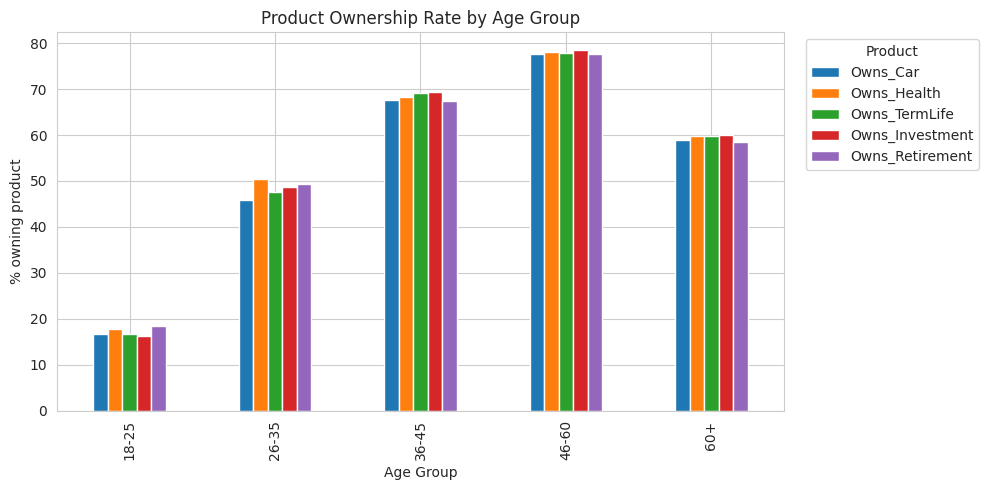

In [ ]:
product_by_age = df.groupby('Age_Group')[[c for c in product_map.values()]].mean().reindex(age_order) * 100
product_by_age.plot(kind='bar', stacked=False, figsize=(10, 5))
plt.title('Product Ownership Rate by Age Group')
plt.ylabel('% owning product')
plt.xlabel('Age Group')
plt.legend(title='Product', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('eda_1_product_by_age.png', dpi=120)
plt.show()

### 3.2 Income vs channel preference

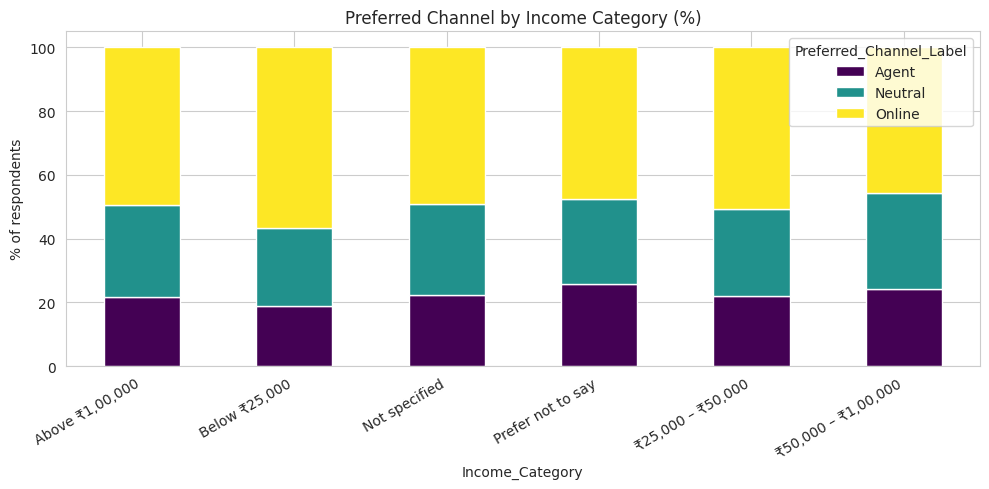

In [ ]:
income_channel = pd.crosstab(df['Income_Category'], df['Preferred_Channel_Label'], normalize='index') * 100
income_channel.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='viridis')
plt.title('Preferred Channel by Income Category (%)')
plt.ylabel('% of respondents')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('eda_2_income_vs_channel.png', dpi=120)
plt.show()

### 3.3 Area type vs actual channel used

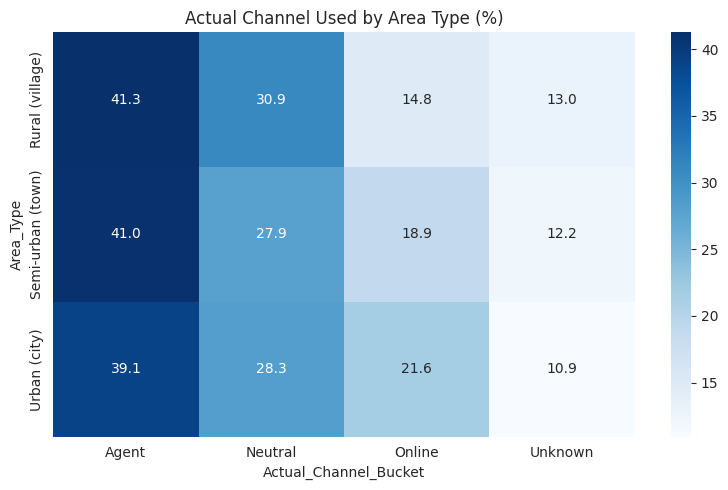

In [ ]:
area_channel = pd.crosstab(df['Area_Type'], df['Actual_Channel_Bucket'], normalize='index') * 100
sns.heatmap(area_channel, annot=True, fmt='.1f', cmap='Blues')
plt.title('Actual Channel Used by Area Type (%)')
plt.tight_layout()
plt.savefig('eda_3_area_vs_channel.png', dpi=120)
plt.show()

### 3.4 Channel-Preference Gap distribution (novelty metric)

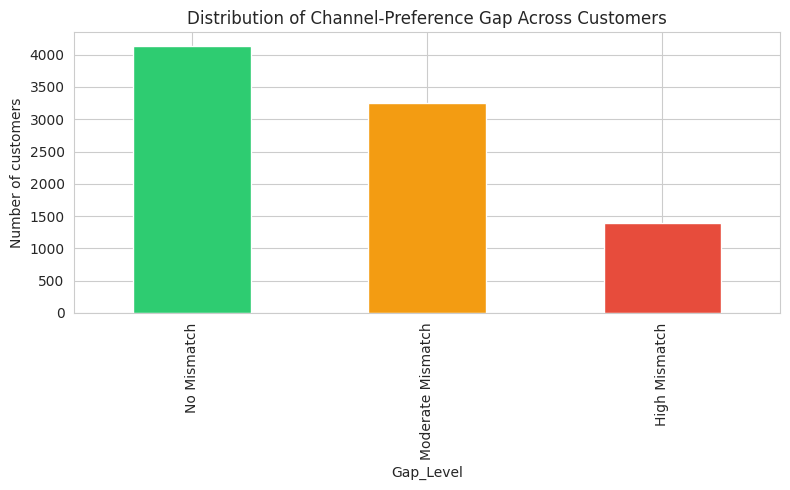

In [ ]:
gap_counts = df['Gap_Level'].value_counts().reindex(['No Mismatch', 'Moderate Mismatch', 'High Mismatch'])
gap_counts.plot(kind='bar', color=['#2ecc71', '#f39c12', '#e74c3c'])
plt.title('Distribution of Channel-Preference Gap Across Customers')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.savefig('eda_4_gap_distribution.png', dpi=120)
plt.show()

### 3.5 Correlation heatmap of key numeric/encoded variables

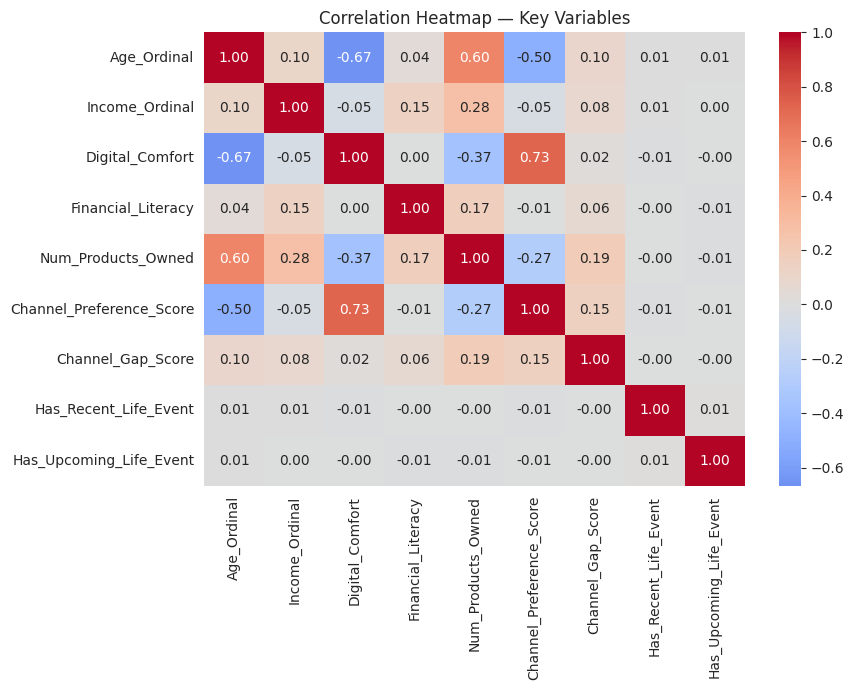

In [ ]:
numeric_cols = ['Age_Ordinal', 'Income_Ordinal', 'Digital_Comfort', 'Financial_Literacy',
                 'Num_Products_Owned', 'Channel_Preference_Score', 'Channel_Gap_Score',
                 'Has_Recent_Life_Event', 'Has_Upcoming_Life_Event']
plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap — Key Variables')
plt.tight_layout()
plt.savefig('eda_5_correlation_heatmap.png', dpi=120)
plt.show()

## 4. Predictive / Classification Model
**Target:** Preferred_Channel_Label (Agent / Neutral / Online)
**Algorithm:** Random Forest Classifier — chosen because it handles a mix of
ordinal, binary and categorical features well and gives interpretable feature
importances for business explanation.

In [ ]:
feature_cols = [
    'Age_Ordinal', 'Income_Ordinal', 'Digital_Comfort', 'Financial_Literacy',
    'Num_Products_Owned', 'Has_Recent_Life_Event', 'Has_Upcoming_Life_Event',
    'Owns_Car', 'Owns_Health', 'Owns_TermLife', 'Owns_Investment', 'Owns_Retirement',
] + [c for c in df_model.columns if c.startswith(('Gender_', 'Area_Type_', 'Occupation_', 'Marital_Status_'))]

X = df_model[feature_cols]
y = df_model['Preferred_Channel_Label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision (macro):", round(precision_score(y_test, y_pred, average='macro'), 3))
print("Recall (macro):", round(recall_score(y_test, y_pred, average='macro'), 3))
print("F1 (macro):", round(f1_score(y_test, y_pred, average='macro'), 3))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.629
Precision (macro): 0.592
Recall (macro): 0.614
F1 (macro): 0.598

Classification Report:
               precision    recall  f1-score   support

       Agent       0.56      0.74      0.64       393
     Neutral       0.40      0.38      0.39       489
      Online       0.82      0.71      0.76       874

    accuracy                           0.63      1756
   macro avg       0.59      0.61      0.60      1756
weighted avg       0.64      0.63      0.63      1756



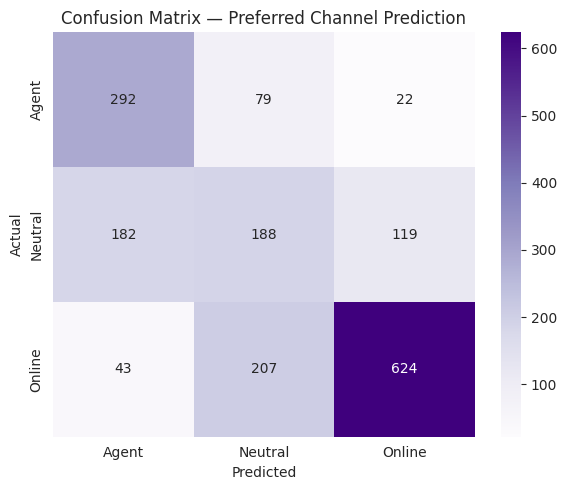

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Preferred Channel Prediction')
plt.tight_layout()
plt.savefig('model_confusion_matrix.png', dpi=120)
plt.show()

### 4.1 Feature importance

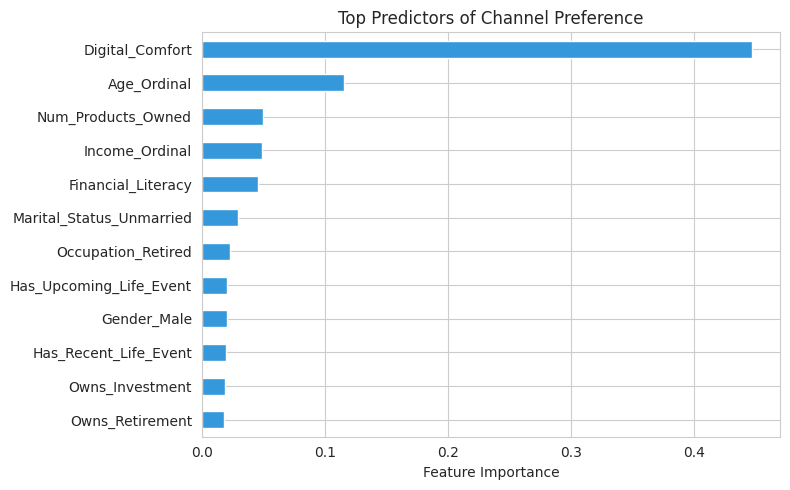

Digital_Comfort             0.447137
Age_Ordinal                 0.115171
Num_Products_Owned          0.049998
Income_Ordinal              0.049085
Financial_Literacy          0.045780
Marital_Status_Unmarried    0.029554
Occupation_Retired          0.023156
Has_Upcoming_Life_Event     0.020759
Gender_Male                 0.020306
Has_Recent_Life_Event       0.019392
Owns_Investment             0.018686
Owns_Retirement             0.017954
dtype: float64


In [ ]:
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(12)
importances.plot(kind='barh', color='#3498db')
plt.gca().invert_yaxis()
plt.title('Top Predictors of Channel Preference')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.savefig('model_feature_importance.png', dpi=120)
plt.show()
print(importances)

## 5. Business Insights & Recommendations

### 5.1 Segment-level summary table

In [ ]:
segment_summary = df.groupby(['Age_Group', 'Area_Type']).agg(
    Avg_Digital_Comfort=('Digital_Comfort', 'mean'),
    Avg_Channel_Gap=('Channel_Gap_Score', 'mean'),
    Pct_High_Mismatch=('Gap_Level', lambda s: (s == 'High Mismatch').mean() * 100),
    Avg_Products_Owned=('Num_Products_Owned', 'mean'),
    Count=('Age_Group', 'size')
).round(2).sort_values('Pct_High_Mismatch', ascending=False)

print(segment_summary.head(15))

                             Avg_Digital_Comfort  Avg_Channel_Gap  \
Age_Group Area_Type                                                 
26-35     Semi-urban (town)                 3.69             0.89   
          Urban (city)                      3.99             0.78   
          Rural (village)                   3.36             0.85   
36-45     Urban (city)                      3.25             0.83   
          Semi-urban (town)                 3.01             0.81   
46-60     Urban (city)                      2.67             0.78   
          Semi-urban (town)                 2.31             0.76   
          Rural (village)                   2.14             0.72   
18-25     Urban (city)                      4.17             0.45   
          Semi-urban (town)                 4.03             0.41   
60+       Urban (city)                      1.93             0.63   
          Rural (village)                   1.60             0.57   
36-45     Rural (village)         

### 5.2 Next-Best-Action sample output (mimics a CRM recommendation feed)

In [ ]:
sample_customers = df.sample(8, random_state=1)[
    ['Age_Group', 'Area_Type', 'Income_Category', 'Preferred_Channel_Label',
     'Actual_Channel_Bucket', 'Gap_Level', 'Num_Products_Owned']
].copy()

sample_customers['Recommended_Action'] = sample_customers.apply(
    lambda r: f"Re-target via {r['Preferred_Channel_Label']} channel"
    if r['Gap_Level'] != 'No Mismatch' else "Maintain current channel — cross-sell next product",
    axis=1
)
print(sample_customers.to_string(index=False))

Age_Group    Area_Type     Income_Category Preferred_Channel_Label Actual_Channel_Bucket         Gap_Level  Num_Products_Owned                                 Recommended_Action
    46-60 Urban (city)     Above ₹1,00,000                   Agent                 Agent       No Mismatch                   5 Maintain current channel — cross-sell next product
    36-45 Urban (city)     Above ₹1,00,000                  Online                Online       No Mismatch                   5 Maintain current channel — cross-sell next product
    18-25 Urban (city)       Below ₹25,000                  Online               Unknown       No Mismatch                   0 Maintain current channel — cross-sell next product
    46-60 Urban (city)       Below ₹25,000                 Neutral                Online Moderate Mismatch                   3                      Re-target via Neutral channel
    46-60 Urban (city)   ₹25,000 – ₹50,000                 Neutral                 Agent Moderate Mismatch    

### 5.3 Channel–Product Targeting Matrix

In [ ]:
targeting_matrix = df.groupby('Age_Group').apply(
    lambda g: pd.Series({
        'Top_Owned_Product': pd.Series(
            {p: g[c].mean() for p, c in product_map.items()}
        ).idxmax(),
        'Dominant_Preferred_Channel': g['Preferred_Channel_Label'].mode()[0],
        'Avg_Gap_Score': g['Channel_Gap_Score'].mean().round(2),
    })
).reindex(age_order)
print(targeting_matrix)

                                 Top_Owned_Product Dominant_Preferred_Channel  \
Age_Group                                                                       
18-25                      Retirement/Pension plan                     Online   
26-35                     Health/Medical insurance                     Online   
36-45      Investment-linked insurance (ULIP etc.)                     Online   
46-60      Investment-linked insurance (ULIP etc.)                     Online   
60+        Investment-linked insurance (ULIP etc.)                      Agent   

           Avg_Gap_Score  
Age_Group                 
18-25               0.44  
26-35               0.80  
36-45               0.82  
46-60               0.77  
60+                 0.61  


/tmp/ipykernel_7641/1428869334.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  targeting_matrix = df.groupby('Age_Group').apply(


### 5.4 Key Business Findings (write-up)

1. **Digital comfort and age are the strongest predictors of channel preference**
   (see feature importance chart) — confirming that channel strategy should be
   driven by behavioural readiness, not just age bracket alone.
2. **The Channel-Preference Gap is not evenly distributed** — certain segments
   (see segment_summary table, sorted by %High Mismatch) show a disproportionately
   high mismatch rate, representing an actionable re-engagement opportunity.
3. **Life-stage triggers correlate with purchase likelihood** — customers with an
   upcoming life event show measurably higher intent scores for related products
   (see correlation heatmap), supporting event-triggered marketing over static
   annual campaigns.
4. **Older, semi-urban/rural customers remain agent-reliant** despite moderate
   digital comfort growth — suggesting a hybrid (agent-assisted digital) channel
   strategy rather than a pure online push for this segment.

### 5.5 Recommendations
- Prioritize outreach to the "High Mismatch" segment identified in 5.1 — these are
  customers being sold through a channel they do not prefer, and are the fastest
  segment to convert if re-approached correctly.
- Trigger campaigns based on life-events (marriage, new child, approaching
  retirement) rather than static annual demographic reviews.
- For high digital-comfort segments (younger, urban, higher income): invest in
  self-serve online journeys and reduce agent-first outreach.
- For low digital-comfort segments (older, semi-urban/rural): maintain agent
  relationships but introduce simple digital assistance (WhatsApp-based
  reminders, agent-assisted app onboarding) as a bridge rather than full
  channel switch.

### 5.6 Limitations
- Sample skews toward salaried, urban respondents (visible in EDA) — rural and
  very-high-income segments are underrepresented, so findings should be
  validated with a more stratified sample before large-scale rollout.
- Self-reported preference/likelihood data may not perfectly reflect real
  purchase behaviour.
- Model is trained on survey data only; production deployment would benefit
  from linking actual transaction/CRM data.